# Individual results: the life periods of Chinese and European individuals

In [1]:
import json
import sys

import duckdb
import matplotlib.pyplot as plt
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely import STRtree, points
from shapely.geometry import shape

sys.path.insert(0, '../notebooks_analysis')
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
BIRTH_YEARS = (700, 799)  # one century of birth
MIN_AGE_AT_DEATH = 15  # years: younger deaths are left out
COUNTRIES_PATH = '../../data/ne_110m_admin_0_countries.geojson'  # Natural Earth present-day borders
REGIONS = {'China': lambda country: country['ISO_A3'] == 'CHN', 'Europe': lambda country: country['CONTINENT'] == 'Europe'}
PER_CASE = {('wikidata', 'wikidata'): 2, ('estimated', 'wikidata'): 2, ('wikidata', 'estimated'): 1}  # individuals shown per region and (birth, death) source
PERIOD_COLORS = {'Pre-peak': ORANGE, 'Peak': BLUE, 'Post-peak': GREEN}

apply_style()

## Data
Individuals born in the century whose Wikidata citizenship (P27) is a polity located, by its Wikidata coordinates, in present-day China or in a present-day European state (Natural Earth borders); citizenships in both regions are left out. Birthplaces are too rare in these centuries (777 of the 15,880 individuals born 700–799). Pre-peak = birth → first work, peak = first → last work, post-peak = last work → death.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
people = con.sql('''
    WITH citizenship AS (
        SELECT entity.qid AS qid, unnest(country_of_citizenship).entity.qid AS polity_qid
        FROM   individual
    )
    SELECT DISTINCT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           place.coordinates.longitude AS longitude,
           place.coordinates.latitude AS latitude,
           len(individual.sitelink)  AS sitelinks,
           individual_enriched.birth_date.year        AS birth_year,
           individual_enriched.birth_date.source      AS birth_source,
           individual_enriched.death_date.year        AS death_year,
           individual_enriched.death_date.source      AS death_source,
           individual_enriched.first_work_date.year   AS peak_start,
           individual_enriched.last_work_date.year    AS peak_end,
           individual_enriched.first_work_date.source AS peak_source
    FROM   individual_enriched
    JOIN   individual ON individual.entity.qid = individual_enriched.entity.qid
    JOIN   citizenship ON citizenship.qid = individual_enriched.entity.qid
    JOIN   place ON place.entity.qid = citizenship.polity_qid
    WHERE  individual_enriched.birth_date.year BETWEEN $first AND $last AND individual_enriched.death_date.year IS NOT NULL
           AND individual_enriched.first_work_date.year IS NOT NULL AND place.coordinates.longitude IS NOT NULL
''', params={'first': BIRTH_YEARS[0], 'last': BIRTH_YEARS[1]}).pl()

countries = json.load(open(COUNTRIES_PATH))['features']
region_shapes = [(region, shape(country['geometry'])) for country in countries for region, inside in REGIONS.items() if inside(country['properties'])]
tree = STRtree([geometry for _, geometry in region_shapes])
spot, shape_index = tree.query(points(people['longitude'].to_numpy(), people['latitude'].to_numpy()), predicate='within')
people = (
    people[spot].with_columns(pl.Series('region', [region_shapes[i][0] for i in shape_index]))
    .drop('longitude', 'latitude').unique()
    .filter(pl.len().over('qid') == 1)
)
con.close()
assert people['qid'].n_unique() == people.height
print(f'{people.height:,} individuals born {BIRTH_YEARS[0]}–{BIRTH_YEARS[1]} with a birth, a death and a work period')
people.group_by('region', 'birth_source', 'death_source').len().sort('region', 'len', descending=[False, True])

12,336 individuals born 700–799 with a birth, a death and a work period


region,birth_source,death_source,len
str,str,str,u32
"""China""","""estimated""","""wikidata""",10038
"""China""","""wikidata""","""wikidata""",1994
"""China""","""wikidata""","""estimated""",48
"""Europe""","""estimated""","""wikidata""",131
"""Europe""","""wikidata""","""wikidata""",106
"""Europe""","""wikidata""","""estimated""",19


## Individuals shown
In each region, the most-linked individuals (Wikipedia pages) of each case: both dates from Wikidata, an estimated birth, an estimated death; named, dead at 15 or older.

In [3]:
shown = pl.concat([
    people.filter((pl.col('region') == region) & (pl.col('birth_source') == birth) & (pl.col('death_source') == death)
                  & pl.col('name').is_not_null() & (pl.col('death_year') - pl.col('birth_year') >= MIN_AGE_AT_DEATH))
    .sort('sitelinks', descending=True).head(n)
    for region in REGIONS for (birth, death), n in PER_CASE.items()
])
assert shown.height == len(REGIONS) * sum(PER_CASE.values())
shown

qid,name,sitelinks,birth_year,birth_source,death_year,death_source,peak_start,peak_end,peak_source,region
str,str,i64,i64,str,i64,str,i64,i64,str,str
"""Q7071""","""Li Bai""",191,701,"""wikidata""",762,"""wikidata""",742,757,"""estimated""","""China"""
"""Q33772""","""Du Fu""",136,712,"""wikidata""",770,"""wikidata""",753,768,"""estimated""","""China"""
"""Q326950""","""Linji Yixuan""",27,793,"""estimated""",867,"""wikidata""",846,863,"""estimated""","""China"""
"""Q1632823""","""Huangbo Xiyun""",16,781,"""estimated""",855,"""wikidata""",834,851,"""estimated""","""China"""
"""Q971072""","""Han Xiang""",16,794,"""wikidata""",868,"""estimated""",847,864,"""estimated""","""China"""
"""Q3044""","""Charlemagne""",184,748,"""wikidata""",814,"""wikidata""",796,814,"""estimated""","""Europe"""
"""Q43974""","""Louis the Pious""",85,778,"""wikidata""",840,"""wikidata""",826,840,"""estimated""","""Europe"""
"""Q233573""","""Offa of Mercia""",49,737,"""estimated""",796,"""wikidata""",785,796,"""estimated""","""Europe"""
"""Q272326""","""Æthelwulf""",48,799,"""estimated""",858,"""wikidata""",847,858,"""estimated""","""Europe"""


## Figure: pre-peak, peak and post-peak periods of Chinese and European individuals born in the 8th century

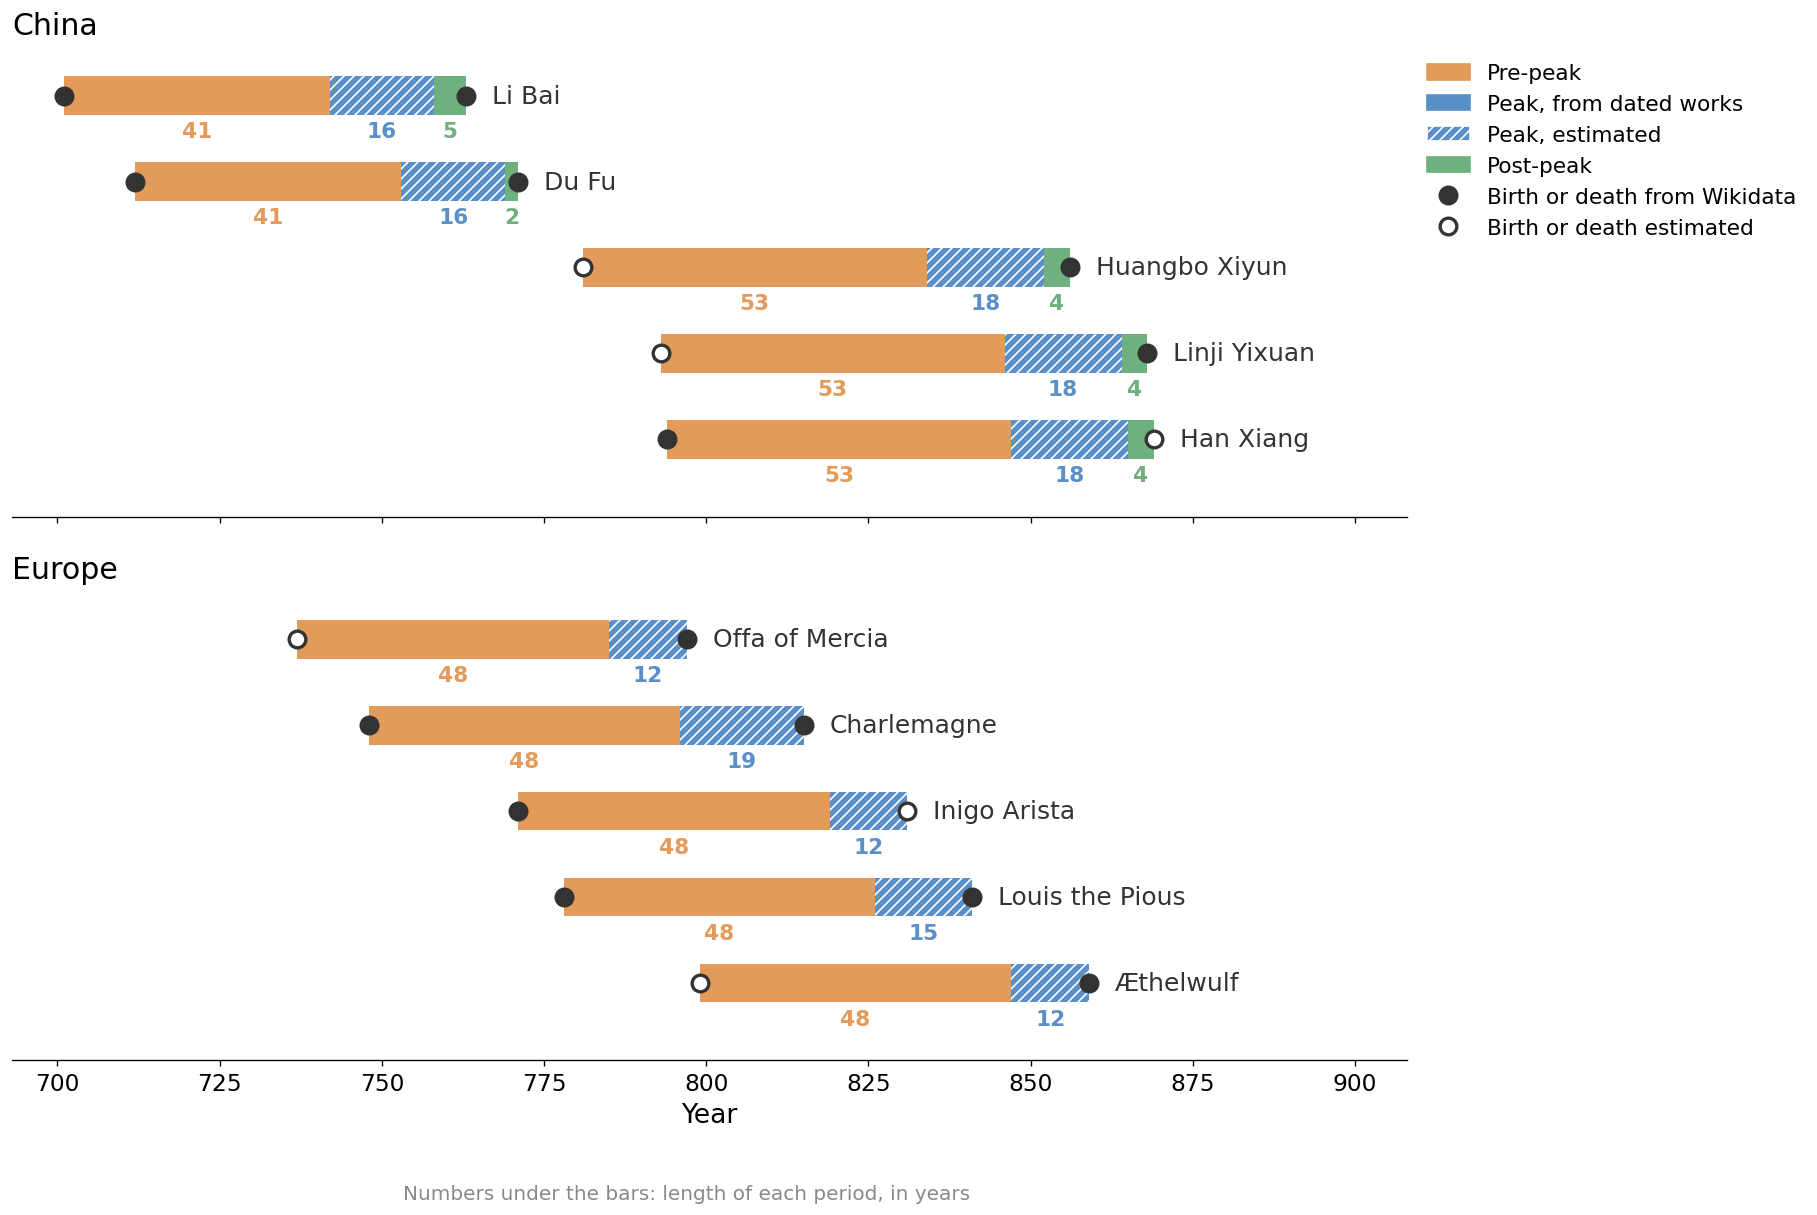

In [4]:
def draw_person(ax, row, person):
    periods = [
        ('Pre-peak', person['birth_year'], person['peak_start']),
        ('Peak', person['peak_start'], person['peak_end'] + 1),
        ('Post-peak', person['peak_end'] + 1, person['death_year'] + 1),
    ]
    for period, start, end in periods:
        if end > start:
            estimated = period == 'Peak' and person['peak_source'] == 'estimated'
            ax.barh(row, end - start, left=start, height=0.45, color=PERIOD_COLORS[period], hatch='////' if estimated else None, edgecolor='white', linewidth=0)
            ax.text((start + end) / 2, row - 0.3, end - start, ha='center', va='top', fontsize=13, color=PERIOD_COLORS[period], fontweight='bold')
    for year, source in [(person['birth_year'], person['birth_source']), (person['death_year'] + 1, person['death_source'])]:
        ax.plot(year, row, 'o', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white' if source == 'estimated' else TEXT, zorder=3)
    ax.text(person['death_year'] + 5, row, person['name'], va='center', fontsize=15, color=TEXT)


fig, axes = plt.subplots(len(REGIONS), 1, figsize=(15, 11), sharex=True, gridspec_kw={'hspace': 0.15})
for ax, region in zip(axes, REGIONS):
    group = shown.filter(pl.col('region') == region).sort('birth_year', descending=True)
    for row, person in enumerate(group.iter_rows(named=True)):
        draw_person(ax, row, person)
    ax.set_title(region, loc='left', fontsize=18, color='black')
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_ylim(-0.9, group.height - 0.4)
axes[-1].set_xlim(shown['birth_year'].min() - 8, shown['death_year'].max() + 40)
axes[-1].set_xlabel('Year')
axes[0].legend(handles=[
    Patch(color=PERIOD_COLORS['Pre-peak'], label='Pre-peak'),
    Patch(color=PERIOD_COLORS['Peak'], label='Peak, from dated works'),
    Patch(facecolor=PERIOD_COLORS['Peak'], hatch='////', edgecolor='white', label='Peak, estimated'),
    Patch(color=PERIOD_COLORS['Post-peak'], label='Post-peak'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, label='Birth or death from Wikidata'),
    Line2D([], [], marker='o', linestyle='', markersize=10, markeredgewidth=2, color=TEXT, markerfacecolor='white', label='Birth or death estimated'),
], loc='upper left', bbox_to_anchor=(1, 1), fontsize=13)
fig.text(0.5, 0.005, 'Numbers under the bars: length of each period, in years', ha='center', fontsize=12, color=MUTED_TEXT)
plt.show()